# Location

first filter based on where people live - only keep the ones that live in the study area

## MATSim

pop file

In [1]:
import gzip
import xml.etree.ElementTree as ET
import pandas as pd

pop_path = r"Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\lausanne_population.xml.gz"

rows = []
with gzip.open(pop_path, "rb") as f:
    for event, elem in ET.iterparse(f, events=("end",)):
        if elem.tag == "person":
            attrs = {a.get("name"): a.text for a in elem.iter("attribute")}
            if "home_coordinate_x" in attrs and "home_coordinate_y" in attrs:
                rows.append({
                    "person_id": elem.get("id"),
                    "x": float(attrs["home_coordinate_x"]),
                    "y": float(attrs["home_coordinate_y"]),
                })
            elem.clear()  # free memory

df = pd.DataFrame(rows)
print(len(df))
df.head()


53442


,person_id,x,y
0,10000901,2539753.0,1139588.0
1,10002135,2540416.0,1139412.0
2,10002202,2540348.0,1139341.0
3,10002205,2535104.0,1139264.0
4,10002640,2535104.0,1139264.0


household file

In [2]:
import gzip
from pathlib import Path
import xml.etree.ElementTree as ET

POP_FILTERED_PATH = Path(r"working_rep\filterred_data\lausanne_population_filtered.xml.gz")
HH_PATH = Path(r"Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\Lausanne_10pct\lausanne_households.xml.gz")
HH_OUT_PATH = Path(r"working_rep\filterred_data\lausanne_households_filtered.xml.gz")
HH_OUT_PATH.parent.mkdir(parents=True, exist_ok=True)


def local(tag):
    """'{ns}household' -> 'household'"""
    return tag.rsplit("}", 1)[-1]


def read_person_ids(path):
    ids = set()
    with gzip.open(path, "rb") as f:
        for event, elem in ET.iterparse(f, events=("end",)):
            if local(elem.tag) == "person":
                ids.add(elem.get("id"))
                elem.clear()
    print(f"Filtered population: {len(ids)} persons")
    return ids


def read_header(path):
    header = []
    with gzip.open(path, "rt", encoding="utf-8") as f:
        for line in f:
            if "<household " in line or "<household>" in line:
                break
            header.append(line)
    return "".join(header)


def strip_ns(elem):
    """Remove namespace prefixes in-place so the output has no ns0: junk."""
    for e in elem.iter():
        e.tag = local(e.tag)


def filter_households(in_path, out_path, person_ids):
    n_total = n_kept = n_partial = 0
    header = read_header(in_path)
    print("Header preview:\n", header[:500])

    with gzip.open(in_path, "rb") as fin, gzip.open(out_path, "wt", encoding="utf-8") as fout:
        fout.write(header)

        context = ET.iterparse(fin, events=("start", "end"))
        root = None
        for event, elem in context:
            if event == "start":
                if root is None:
                    root = elem
                continue

            if local(elem.tag) != "household":
                continue

            n_total += 1
            members = [p.get("refId")
                       for p in elem.iter()
                       if local(p.tag) == "personId"]
            n_in = sum(m in person_ids for m in members)

            if n_in > 0:
                n_kept += 1
                if n_in < len(members):
                    n_partial += 1
                strip_ns(elem)  # serialize without namespace prefixes
                fout.write("\t" + ET.tostring(elem, encoding="unicode").strip() + "\n")

            elem.clear()
            root.clear()

        fout.write("</households>\n")

    print(f"Households: {n_total} total, {n_kept} kept")
    print(f"  of which {n_partial} have members both inside and outside the area")
    return n_kept


if __name__ == "__main__":
    person_ids = read_person_ids(POP_FILTERED_PATH)
    filter_households(HH_PATH, HH_OUT_PATH, person_ids)
    print(f"Saved to {HH_OUT_PATH.resolve()}")

Filtered population: 34461 persons
Header preview:
 <?xml version="1.0" encoding="UTF-8"?>

<households xmlns="http://www.matsim.org/files/dtd" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xsi:schemaLocation="http://www.matsim.org/files/dtd http://www.matsim.org/files/dtd/households_v1.0.xsd">

Households: 32012 total, 15987 kept
  of which 0 have members both inside and outside the area
Saved to C:\Users\Sylvain\Documents\GitHub\abmt-2026\ass_2\working_rep\filterred_data\lausanne_households_filtered.xml.gz


map of pop file

Boundary CRS: EPSG:2056
34461 of 53442 persons inside the boundary
Written: working_rep\filterred_data\lausanne_population_filtered.xml.gz


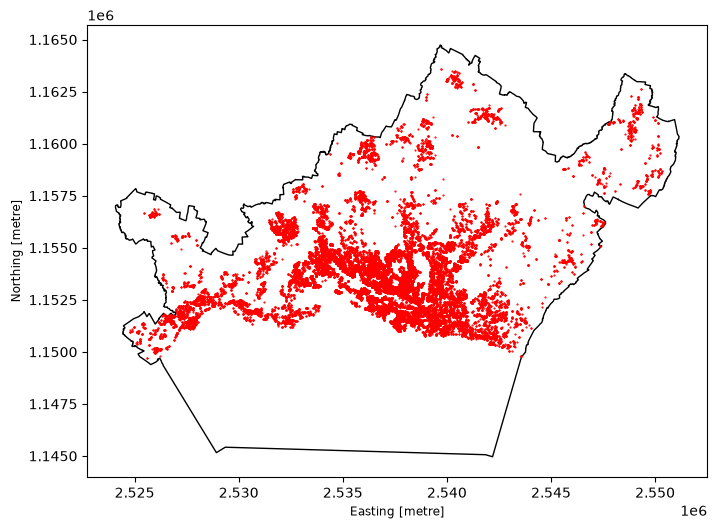

In [ ]:
import os, gzip
import geopandas as gpd
import xml.etree.ElementTree as ET

boundary_path = r"Lausanne_10pct\Lausanne_10pct\Boundary\LausanneExtent.shp"
out_dir = r"working_rep\filterred_data"
os.makedirs(out_dir, exist_ok=True)

# 1. Load boundary and make sure it's in LV95
boundary = gpd.read_file(boundary_path)
print("Boundary CRS:", boundary.crs)
boundary = boundary.to_crs("EPSG:2056")   # if CRS is None, use .set_crs("EPSG:2056") instead

# 2. Spatial filter using the df you already built
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.x, df.y), crs="EPSG:2056")
inside = gpd.sjoin(gdf, boundary[["geometry"]], predicate="within", how="inner")
inside = inside.drop_duplicates("person_id")
keep_ids = set(inside["person_id"])
print(f"{len(keep_ids)} of {len(df)} persons inside the boundary")

# quick visual check
ax = boundary.plot(facecolor="none", edgecolor="black", figsize=(8, 8))
inside.plot(ax=ax, markersize=0.3, color="red")

# 3. Save a CSV of kept home locations
inside[["person_id", "x", "y"]].to_csv(os.path.join(out_dir, "persons_in_perimeter.csv"), index=False)

# 4. Write the filtered MATSim population (streamed)
out_path = os.path.join(out_dir, "lausanne_population_filtered_lives_area.xml.gz")
with gzip.open(pop_path, "rb") as fin, gzip.open(out_path, "wb") as fout:
    fout.write(b'<?xml version="1.0" encoding="utf-8"?>\n')
    fout.write(b'<!DOCTYPE population SYSTEM "http://www.matsim.org/files/dtd/population_v6.dtd">\n')
    fout.write(b"<population>\n")
    for event, elem in ET.iterparse(fin, events=("end",)):
        if elem.tag == "person":
            if elem.get("id") in keep_ids:
                fout.write(ET.tostring(elem, encoding="utf-8"))
            elem.clear()
    fout.write(b"</population>\n")

print("Written:", out_path)

## MZ

In [6]:
import pandas as pd
import geopandas as gpd

hh_path = r"Lausanne_10pct\Lausanne_10pct\Mikrozensus\microcensus\haushalte.csv"
boundary_path = r"Lausanne_10pct\Lausanne_10pct\Boundary\LausanneExtent.shp"

# 1. Load (adjust sep / encoding if the columns look wrong)
hh = pd.read_csv(hh_path, sep=None, engine="python", encoding="latin-1")
print(hh.shape)
print(hh[["HHNR", "W_X", "W_Y", "W_X_CH1903", "W_Y_CH1903"]].describe())

# 2. Check missing / placeholder values (MZ often uses negative codes like -99)
cols = ["W_X_CH1903", "W_Y_CH1903"]
print((hh[cols] <= 0).sum())

(57090, 106)
                HHNR           W_X           W_Y     W_X_CH1903     W_Y_CH1903
count   57090.000000  57090.000000  57090.000000   57090.000000   57090.000000
mean   286484.430846      7.882868     46.990164  633447.012314  204923.957103
std    116244.667683      0.996770      0.475816   75968.881513   52899.472341
min    100004.000000      5.969560     45.820370  486495.000000   75517.000000
25%    183529.500000      7.066628     46.612565  571493.250000  162642.500000
50%    278938.000000      7.975830     47.096920  640737.500000  216563.000000
75%    385642.750000      8.682878     47.392200  694026.250000  249719.750000
max    499998.000000     10.453850     47.793930  830847.000000  294361.000000
W_X_CH1903    0
W_Y_CH1903    0
dtype: int64


57090 of 57090 households have valid coordinates
1943 households inside the study area


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

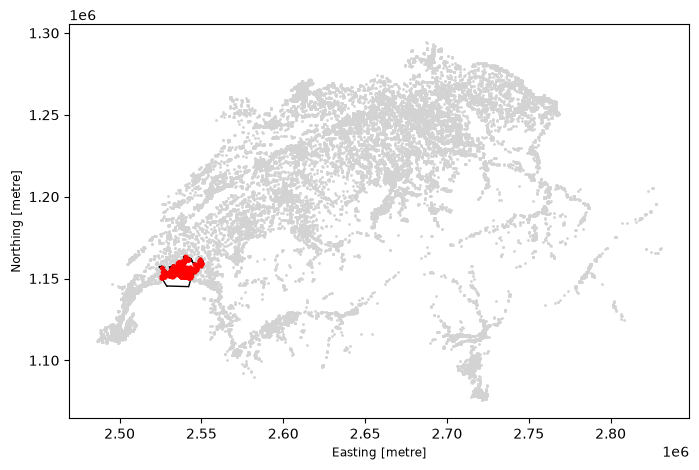

In [9]:
# 3. Clean and build points  (set east/north according to the check above)
east_col, north_col = "W_X_CH1903", "W_Y_CH1903"     # swap if needed

valid = hh[(hh[east_col] > 0) & (hh[north_col] > 0)].copy()
print(f"{len(valid)} of {len(hh)} households have valid coordinates")

gdf = gpd.GeoDataFrame(
    valid,
    geometry=gpd.points_from_xy(valid[east_col], valid[north_col]),
    crs="EPSG:21781",            # CH1903 / LV03
).to_crs("EPSG:2056")            # LV95, same as the boundary

# 4. Spatial filter
boundary = gpd.read_file(boundary_path).to_crs("EPSG:2056")
hh_in = gpd.sjoin(gdf, boundary[["geometry"]], predicate="within", how="inner")
hh_in = hh_in.drop_duplicates("HHNR")
hh_in[["HHNR"]].to_csv(r"working_rep\filterred_data\mz\household_ids_in_area.csv", index=False)

print(f"{len(hh_in)} households inside the study area")

# 5. Visual check
ax = boundary.plot(facecolor="none", edgecolor="black", figsize=(8, 8))
gdf.plot(ax=ax, markersize=1, color="lightgrey")
hh_in.plot(ax=ax, markersize=3, color="red")

In [5]:
boundary_path

'Boundary\\LausanneExtent.shp'